# Exploratory data analysis

Six questions on sessions, jobs and targets, to guide the first baselines.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hrflow_recsys.data import load_data

SEED = 42

x_train, y_train, x_test, jobs = load_data()
train = x_train.merge(y_train, on="session_id")
len(x_train), len(x_test), len(jobs)

(15882, 1819, 21917)

## 1. Session length

In [2]:
train_len = x_train["job_ids"].map(len)
test_len = x_test["job_ids"].map(len)
pd.DataFrame({"train": train_len.describe(), "test": test_len.describe()}).round(1)

,train,test
count,15882.0,1819.0
mean,7.5,7.6
std,3.6,3.6
min,3.0,3.0
25%,4.0,5.0
50%,7.0,7.0
75%,10.0,10.0
max,15.0,15.0


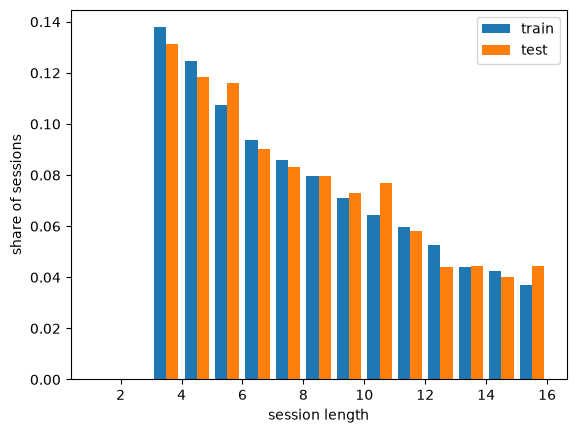

In [3]:
bins = np.arange(1, max(train_len.max(), test_len.max()) + 2)
plt.hist([train_len, test_len], bins=bins, density=True, label=["train", "test"])
plt.xlabel("session length")
plt.ylabel("share of sessions")
plt.legend();

Sessions have 3 to 15 jobs (median 7) and train and test follow the same length distribution.

## 2. Job popularity

Clicks are all interactions (view or apply) in the train and test histories.

In [4]:
clicks = pd.concat([x_train["job_ids"], x_test["job_ids"]]).explode().value_counts()
top_n = int(np.ceil(0.01 * len(clicks)))
top_share = clicks.iloc[:top_n].sum() / clicks.sum()
len(clicks), top_n, round(float(top_share), 3)

(21449, 215, 0.147)

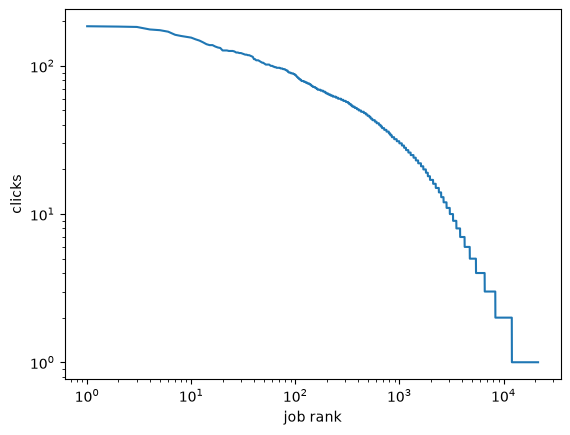

In [5]:
plt.loglog(np.arange(1, len(clicks) + 1), clicks.to_numpy())
plt.xlabel("job rank")
plt.ylabel("clicks");

The top 1 % of jobs (215 out of 21,449 clicked) capture only 14.7 % of clicks: popularity is a weak signal and the catalogue is long-tail.

## 3. Apply rate

In [6]:
history_actions = x_train["actions"].explode()
pd.Series(
    {
        "history": (history_actions == "apply").mean(),
        "target": (y_train["action"] == "apply").mean(),
    }
).round(3)

history    0.364
target     0.395
dtype: float64

Applies are frequent: 36.4 % of history actions and 39.5 % of targets, so predicting the action is close to balanced.

## 4. Target already in the session history

In [7]:
in_history = train.apply(lambda row: row["job_id"] in row["job_ids"], axis=1)
round(float(in_history.mean()), 3)

0.006

Only 0.6 % of targets were already seen in the session: recommending from the history is useless, so history jobs can be excluded.

## 5. Cold-start targets

Share of targets that never appear in any train history.

In [8]:
seen = set(x_train["job_ids"].explode())
cold = ~y_train["job_id"].isin(seen)
round(float(cold.mean()), 3)

0.03

3.0 % of targets never appear in a train history, so a model limited to seen jobs loses at most 3 % of sessions.

## 6. Distance between the target id and the last job id

In [9]:
last_job = x_train["job_ids"].map(lambda ids: ids[-1])
gap = (y_train["job_id"] - last_job).abs()

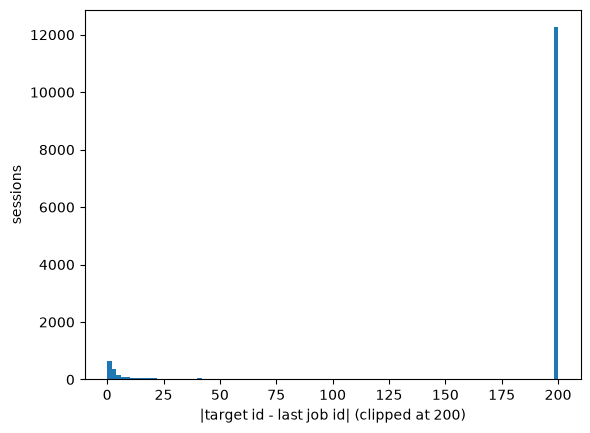

In [10]:
plt.hist(gap.clip(upper=200), bins=100)
plt.xlabel("|target id - last job id| (clipped at 200)")
plt.ylabel("sessions");

In [11]:
rng = np.random.default_rng(SEED)
random_target = rng.choice(jobs.index.to_numpy(), size=len(last_job))
random_gap = np.abs(random_target - last_job)
thresholds = [0, 1, 5, 10, 50, 100]
pd.DataFrame(
    {
        "target": [(gap <= d).mean() for d in thresholds],
        "random": [(random_gap <= d).mean() for d in thresholds],
    },
    index=[f"<= {d}" for d in thresholds],
).round(3)

,target,random
<= 0,0.005,0.000
<= 1,0.041,0.000
<= 5,0.073,0.001
<= 10,0.086,0.001
<= 50,0.130,0.004
<= 100,0.169,0.009


16.9 % of targets are within 100 ids of the last job against 0.9 % for random job ids (4.1 % vs 0.0 % within 1): close ids tend to follow each other.